In [2]:
from google.colab import drive
import pandas as pd

In [3]:
aml = drive.mount("/content/drive/")
aml = "/content/drive/MyDrive/aml.csv"
try:
    aml = pd.read_csv(aml)
    print("Success reading aml")
except Exception as e:
    print(type(e).__name__, "-", str(e))


Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).
Success reading aml


In [4]:
aml.head(10)

,date,category,amount_in,amount_out,balance
0,2026-10-29 17:04:54,send_money,0.0,-40.0,1514.05
1,2026-10-29 13:54:30,buy_goods,0.0,-150.0,1554.05
2,2026-10-29 10:40:43,buy_goods,0.0,-50.0,1704.05
3,2026-10-29 10:21:29,pochi,0.0,-30.0,1754.05
4,2026-10-28 21:32:07,receive_money,1000.0,0.0,1784.05
5,2026-10-28 14:53:54,pochi,0.0,-60.0,784.05
6,2026-10-28 14:05:36,send_money,0.0,-150.0,851.05
7,2026-10-28 14:05:36,transaction_fee,0.0,-7.0,844.05
8,2026-10-28 13:17:31,pochi,0.0,-40.0,1001.05
9,2026-10-28 10:53:53,data_bundle,0.0,-20.0,1041.05


In [5]:
print(aml.shape)
print(aml.dtypes)

(3076, 5)
date           object
category       object
amount_in     float64
amount_out    float64
balance       float64
dtype: object


In [6]:
aml['date'] = pd.to_datetime(aml['date'], errors="coerce")
print("Unparseable dates include:", aml['date'].isna().sum())
aml = aml.dropna(subset=["date"]).copy()
aml.head()


Unparseable dates include: 0


,date,category,amount_in,amount_out,balance
0,2026-10-29 17:04:54,send_money,0.0,-40.0,1514.05
1,2026-10-29 13:54:30,buy_goods,0.0,-150.0,1554.05
2,2026-10-29 10:40:43,buy_goods,0.0,-50.0,1704.05
3,2026-10-29 10:21:29,pochi,0.0,-30.0,1754.05
4,2026-10-28 21:32:07,receive_money,1000.0,0.0,1784.05


In [7]:
print("Earliest transaction:", aml['date'].min())
print("Latest transaction:", aml['date'].max())
print("Total days", (aml['date'].max()-aml['date'].min() ).days)

Earliest transaction: 2024-04-26 16:10:20
Latest transaction: 2026-10-29 17:04:54
Total days 916


In [8]:
print(aml['category'].value_counts)
print("Percent 'other':", (aml['category']=='other').mean()*100)

<bound method IndexOpsMixin.value_counts of 0             send_money
1              buy_goods
2              buy_goods
3                  pochi
4          receive_money
              ...       
3071           buy_goods
3072       receive_money
3073    bank_transfer_in
3074          send_money
3075    bank_transfer_in
Name: category, Length: 3076, dtype: object>
Percent 'other': 0.8452535760728219


In [9]:
for c in ["amount_in", "amount_out", "balance"]:
    aml[c] = pd.to_numeric(aml[c], errors="coerce")
aml["category"] = aml["category"].fillna("other").astype(str).str.strip().str.lower()
aml = aml.sort_values("date").drop_duplicates().reset_index(drop= True)
print("Clean shape:", aml.shape)
print("Date range:", aml["date"].min(), aml["date"].max())
print(aml.isna().sum())


Clean shape: (3076, 5)
Date range: 2024-04-26 16:10:20 2026-10-29 17:04:54
date          0
category      0
amount_in     0
amount_out    0
balance       0
dtype: int64


In [10]:
print("Shape:", aml.shape)
print("Date range:", aml['date'].min(), "to", aml['date'].max())
print("Total Days covered:", (aml['date'].max()-aml['date'].min()).days)
print("\nCategory breakdown:")
print(aml['category'].value_counts())
print("\nPercentage 'other':", (aml['category']=='other').mean()*100, "%")

Shape: (3076, 5)
Date range: 2024-04-26 16:10:20 to 2026-10-29 17:04:54
Total Days covered: 916

Category breakdown:
category
send_money          790
pochi               679
buy_goods           470
transaction_fee     317
receive_money       198
pay_bill            186
airtime             133
data_bundle         130
bank_transfer_in     64
agent_withdrawal     31
mshwari_withdraw     31
other                26
mshwari_deposit      14
reversal              5
agent_deposit         2
Name: count, dtype: int64

Percentage 'other': 0.8452535760728219 %


In [11]:
aml = aml.sort_values('date').reset_index(drop=True)
aml['day'] = aml['date'].dt.date
daily = aml.groupby('day').agg(
    total_out=('amount_out', lambda x: -x.sum()),
    total_in=('amount_in', 'sum'),
    n_transactions=('category','count'),
    end_balance=('balance', 'last')
).reset_index()
print(daily.describe())

          total_out      total_in  n_transactions   end_balance
count    721.000000    721.000000      721.000000    721.000000
mean     764.494854    766.969265        4.266297   8284.455479
std     1721.989175   1936.500792        2.604716   6096.041176
min       -0.000000      0.000000        1.000000     19.050000
25%      150.000000      0.000000        2.000000   1900.050000
50%      260.000000      0.000000        4.000000   8726.050000
75%      500.000000    600.000000        5.000000  13400.000000
max    20449.000000  20350.000000       22.000000  20531.050000


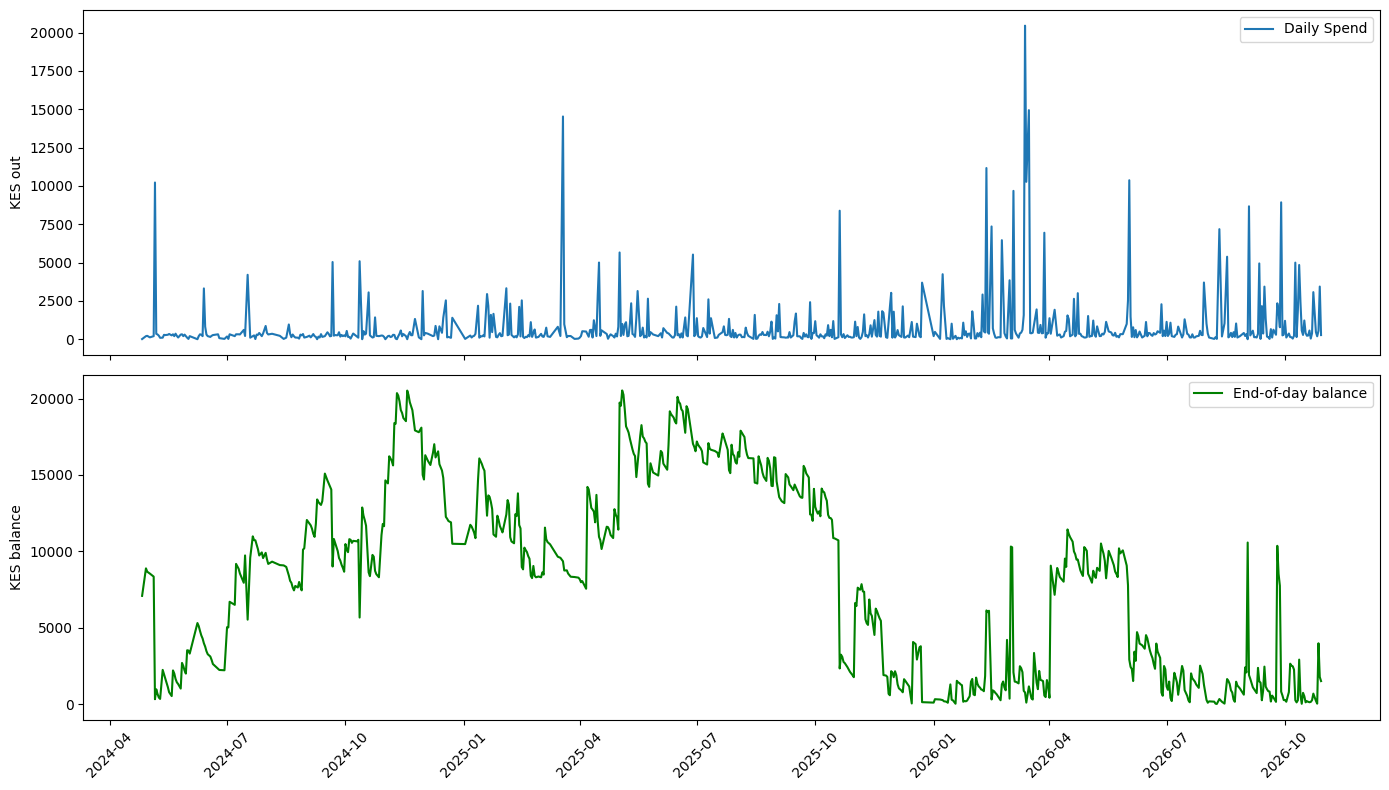


Days with spend > mean + 2 * std (4208 KES):
            day  total_out  total_in  n_transactions  end_balance
5    2024-05-06    10220.0    2200.0               7       330.00
100  2024-09-21     5034.0       0.0               6      9011.00
119  2024-10-12     5086.0       0.0               4      5673.00
231  2025-03-19    14527.0   14300.0               6      9354.00
251  2025-04-16     5001.0    4000.0               9     10951.00
263  2025-05-02     5657.0   13980.0              11     19736.05
309  2025-06-28     5520.0    3250.0               6     17040.05
408  2025-10-20     8380.0       0.0               9      2342.05
468  2026-01-08     4239.0    4200.0              13       271.05
499  2026-02-11    11164.0   15400.0               8      6137.05
502  2026-02-15     7354.0    1550.0              18       312.05
510  2026-02-23     6459.0    7500.0               6      1302.05
518  2026-03-04     9675.0    1500.0               8      2092.05
526  2026-03-13    20449.0   2

In [12]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2,1,figsize=(14,8), sharex=True)
axes[0].plot(daily['day'], daily['total_out'], label='Daily Spend')
axes[0].set_ylabel('KES out')
axes[0].legend()
axes[1].plot(daily['day'], daily['end_balance'],color='green',  label='End-of-day balance')
axes[1].set_ylabel('KES balance')
axes[1].legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
threshold = daily['total_out'].mean()+ 2 * daily['total_out'].std()
print(f"\nDays with spend > mean + 2 * std ({threshold:.0f} KES):")
print(daily[daily['total_out'] > threshold])

In [13]:
column_dictionary = {
    "date": "Transaction date parsed from the statement; used for chronological and monthly analysis.",
    "category": "Category assigned by the parser; labels may need manual correction.",
    "amount_in": "Incoming cash-flow amount. This describes money entering M-Pesa, not necessarily earned income.",
    "amount_out": "Outgoing cash-flow amount. This describes money leaving M-Pesa, not necessarily consumption.",
    "balance": "Balance reported by the parser. Confirm its timing and meaning against the original statement before using it.",
}
display(pd.DataFrame.from_dict(column_dictionary, orient="index", columns=["meaning"]).rename_axis("column"))

category_dictionary = {
    "airtime": ("direct_spend_candidate", "Airtime purchase; confirm parser classification."),
    "buy_goods": ("direct_spend_candidate", "Merchant/goods payment; likely consumption."),
    "data_bundle": ("direct_spend_candidate", "Data bundle purchase; likely consumption."),
    "transaction_fee": ("direct_spend_candidate", "Payment fee; count separately or include as a cost."),
    "pay_bill": ("needs_manual_review", "Bill payment; identify what the bill paid for."),
    "pochi": ("needs_manual_review", "Pochi transaction; confirm whether it is a purchase, transfer, or receipt."),
    "agent_withdrawal": ("cash_withdrawal_review", "Cash withdrawal; later cash spending is not visible here."),
    "send_money": ("transfer_or_payment_review", "Money sent; determine recipient/purpose before calling it spending."),
    "mshwari_deposit": ("savings_transfer_candidate", "M-Shwari movement; observed as an outflow, not automatically consumption."),
    "mshwari_withdraw": ("savings_transfer_candidate", "M-Shwari movement; observed as an inflow, not automatically income."),
    "bank_transfer_in": ("inflow_candidate", "Incoming bank transfer; source and purpose are not specified here."),
    "receive_money": ("inflow_candidate", "Incoming receipt; source and purpose are not specified here."),
}

aml["direction"] = "zero_or_invalid"
aml.loc[aml["amount_in"].ne(0), "direction"] = "inflow"
aml.loc[aml["amount_out"].ne(0), "direction"] = "outflow"
aml["candidate_group"] = aml["category"].map(
    {category: details[0] for category, details in category_dictionary.items()}
).fillna("unmapped_review")

category_review = (
    aml.groupby(["category", "candidate_group", "direction"], dropna=False)
    .size()
    .rename("transaction_count")
    .reset_index()
    .sort_values(["candidate_group", "category", "direction"])
)
display(category_review)



,meaning
column,
date,Transaction date parsed from the statement; us...
category,Category assigned by the parser; labels may ne...
amount_in,Incoming cash-flow amount. This describes mone...
amount_out,Outgoing cash-flow amount. This describes mone...
balance,Balance reported by the parser. Confirm its ti...


,category,candidate_group,direction,transaction_count
1,agent_withdrawal,cash_withdrawal_review,outflow,31
2,airtime,direct_spend_candidate,outflow,133
4,buy_goods,direct_spend_candidate,outflow,470
5,data_bundle,direct_spend_candidate,outflow,130
14,transaction_fee,direct_spend_candidate,outflow,317
3,bank_transfer_in,inflow_candidate,inflow,64
11,receive_money,inflow_candidate,inflow,198
9,pay_bill,needs_manual_review,outflow,186
10,pochi,needs_manual_review,outflow,679
6,mshwari_deposit,savings_transfer_candidate,outflow,14


In [14]:
aml["outflow_kes"] = aml["amount_out"].abs()
aml["month"] = aml["date"].dt.to_period("M").astype(str)
monthly_category_outflow = (

        aml.pivot_table(
            index="month",
            columns="category",
            values="outflow_kes",
            aggfunc="sum",
            fill_value=0,
        ).sort_index()
)
monthly_outflow =(
    monthly_category_outflow.sum(axis=1).rename("total_outflow_kes").to_frame()
)
display(monthly_outflow)
display(monthly_category_outflow)


,total_outflow_kes
month,
2024-04,430.00
2024-05,15966.00
2024-06,6910.00
2024-07,9674.00
2024-08,4594.00
2024-09,10966.00
2024-10,14196.04
2024-11,9044.00
2024-12,9554.00


category,agent_deposit,agent_withdrawal,airtime,bank_transfer_in,buy_goods,data_bundle,mshwari_deposit,mshwari_withdraw,other,pay_bill,pochi,receive_money,reversal,send_money,transaction_fee
month,,,,,,,,,,,,,,,
2024-04,0.0,0.0,20.0,0.0,100.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,310.0,0.0
2024-05,0.0,80.0,140.0,0.0,1645.0,0.0,10000.0,0.0,290.0,600.00,140.0,0.0,0.0,3060.0,11.0
2024-06,0.0,0.0,60.0,0.0,890.0,0.0,0.0,0.0,270.0,600.00,250.0,0.0,0.0,4780.0,60.0
2024-07,0.0,0.0,40.0,0.0,1237.0,0.0,0.0,0.0,250.0,1160.00,160.0,0.0,0.0,6730.0,97.0
2024-08,0.0,0.0,20.0,0.0,1232.0,0.0,0.0,0.0,330.0,1230.00,400.0,0.0,0.0,1360.0,22.0
2024-09,0.0,4700.0,80.0,0.0,1015.0,0.0,0.0,0.0,410.0,1755.00,870.0,0.0,0.0,2040.0,96.0
2024-10,0.0,0.0,0.0,0.0,1600.0,40.0,0.0,0.0,350.0,734.04,730.0,0.0,0.0,10590.0,152.0
2024-11,0.0,160.0,20.0,0.0,1365.0,310.0,0.0,0.0,0.0,600.00,690.0,0.0,0.0,5780.0,119.0
2024-12,0.0,0.0,20.0,0.0,3006.0,0.0,0.0,0.0,0.0,1190.00,260.0,0.0,0.0,5020.0,58.0


In [15]:
from math import sqrt
daily_outflow = (
    aml.set_index("date")["amount_out"].abs().resample("D").sum()

)
holdout_days = 30
if len(daily_outflow) <= holdout_days:
    raise ValueError("Not enough daily history for the specified holdout period.")
split_at = len(daily_outflow) - holdout_days
actual = daily_outflow.iloc[split_at:]
predicted = pd.Series(
    [
        daily_outflow.iloc[max(0, day_index - 30): day_index].mean()
        for day_index in range(split_at, len(daily_outflow))
    ],
    index=actual.index,
    name="predicted_gross_outflow"
)
mae = (actual - predicted).abs().mean() 
rmse = sqrt(((actual - predicted) ** 2).mean()) 
print("Measure: daily gross M-Pesa outflow not confirmed consumption spending")
print(f"Evaluation days:{len(actual)}")
print(f"Holdout period: {actual.index.min().date()} to {actual.index.max().date()}")
print(f"MAE in KES: {mae:.2f}")
print(f"RMSE in KES: {rmse:.2f}")

Measure: daily gross M-Pesa outflow not confirmed consumption spending
Evaluation days:30
Holdout period: 2026-09-30 to 2026-10-29
MAE in KES: 1138.69
RMSE in KES: 1412.97


In [16]:
previous_day_prediction = daily_outflow.shift(1).iloc[split_at:]
previous_day_mae = (actual - previous_day_prediction).abs().mean()
previous_day_rmse = sqrt(((actual - previous_day_prediction) ** 2).mean())
print(f"Previous day MAE in KES: {previous_day_mae:.2f}")
print(f"Previous day RMSE in KES: {previous_day_rmse:.2f}")
print(f"30-day MAE in KES: {mae:.2f}")
print(f"30-day RMSE in KES: {rmse:.2f}")

Previous day MAE in KES: 1266.07
Previous day RMSE in KES: 1889.89
30-day MAE in KES: 1138.69
30-day RMSE in KES: 1412.97


In [17]:
difference_mse = previous_day_mae - mae
difference_rmse =  previous_day_rmse - rmse
print(f"Difference in MAE: {difference_mse:.2f}")
print(f"Difference in RMSE: {difference_rmse:.2f}")

Difference in MAE: 127.37
Difference in RMSE: 476.93


The 30 day rolling average performed better. MAE was lower by Kes 457.18 and RMSE was lower by 818.71

## Synthetic Outflow Dataset
This generates simulated outflow transactions using category frequencies and amount distributions estimated from own  M-Pesa Pilot. Generated rows are synthetic and are not copied transactions. Purposes of the dataset is for testing the pipeline not evidence of perfomance across students

In [18]:
import numpy as np
import pandas as pd

In [19]:
required_columns = {"date", "category","amount_out"}
missing_columns = required_columns - set(aml.columns)
if missing_columns:
    raise ValueError(f"aml is missing required columns:{sorted(missing_columns)}")
pilot_outflows = aml.loc[aml["amount_out"] < 0, ["date", "category", "amount_out"]].copy()
pilot_outflows["date"] = pd.to_datetime(pilot_outflows["date"], errors="coerce")
pilot_outflows["category"]= pilot_outflows["category"].astype(str).str.strip().str.lower()
pilot_outflows["amount_kes"] = pilot_outflows["amount_out"].abs()
pilot_outflows = pilot_outflows.dropna(subset=["date", "category", "amount_kes"])
pilot_outflows = pilot_outflows.loc[pilot_outflows["amount_kes"] > 0].copy()
if pilot_outflows.empty:
    raise ValueError("No valid pilot outflows found.")
random_generator = np.random.default_rng(20260930)
number_of_students = 20
simulation_days = 180
injected_anomaly_fraction = 0.01
pilot_start = pilot_outflows["date"].min().normalize()
pilot_end = pilot_outflows["date"].max().normalize()
pilot_calendar_days = (pilot_end - pilot_start).days + 1
mean_daily_transaction_count = len(pilot_outflows) / pilot_calendar_days
category_probabilities = pilot_outflows["category"].value_counts(normalize=True)
category_names = category_probabilities.index.to_numpy()
category_weights = category_probabilities.to_numpy()
amount_parameters = {}
for category, group in pilot_outflows.groupby("category"):
    log_amounts = np.log(group["amount_kes"].to_numpy())
    log_mean = float(log_amounts.mean())
    log_std = float(log_amounts.std(ddof=1)) if len(log_amounts) > 1 else 0.1
    amount_parameters[category] = (log_mean, max(log_std, 0.1))
synthetic_start = pilot_end + pd.Timedelta(days=1)
records=[]
for student_number in range(1, number_of_students + 1):
    student_id = f"SYN{student_number:04d}"
    student_scale = random_generator.lognormal(mean=0.0, sigma = 0.2)
    for day_offset in range(simulation_days):
        transaction_count = random_generator.poisson(mean_daily_transaction_count)
        for _ in range(transaction_count):
                category = random_generator.choice(category_names, p=category_weights)
                log_mean, log_std = amount_parameters[category]
                amount = random_generator.lognormal(log_mean, log_std) * student_scale
                minute_of_day = int(random_generator.integers(0, 24*60))
                timestamp = synthetic_start + pd.Timedelta(days=day_offset, minutes=minute_of_day)
                records.append({
                    "student_id": student_id,
                    "timestamp": timestamp,
                    "category": category,
                    "amount_kes": round(float(amount), 2),
                    "direction": "outflow",
                    "is_anomaly": False,
                    "anomaly_type": "normal",
                    "is_synthetic": True,

                })

synthetic_transactions = pd.DataFrame(records)
if synthetic_transactions.empty:
    raise ValueError("No synthetic transactions were generated.Review frequency and simulation parameters.")
anomaly_count = max(1, int(len(synthetic_transactions) * injected_anomaly_fraction))
anomaly_indices = random_generator.choice(synthetic_transactions.index.to_numpy(), size=min(anomaly_count, len(synthetic_transactions)), replace=False)
synthetic_transactions.loc[anomaly_indices, "is_anomaly"] = True
synthetic_transactions.loc[anomaly_indices, "anomaly_type"] = "injected"
synthetic_transactions.loc[anomaly_indices, "amount_kes"] *= 4
print(f"Synthetic transactions generated: {len(synthetic_transactions)}")
print(f"Synthetic students: {synthetic_transactions['student_id'].nunique()}")
print(f"Synthetic Date Range: {synthetic_transactions['timestamp'].min().date()} to {synthetic_transactions['timestamp'].max().date()}")
print(f"Synthetic anomalies injected: {int(synthetic_transactions['is_anomaly'].sum()):}")
print(f"All rows synthetic: {bool(synthetic_transactions['is_synthetic'].all())}")
display(
    synthetic_transactions.groupby(["category", "is_anomaly"]).size().rename("row_count").reset_index()
)



Synthetic transactions generated: 10677
Synthetic students: 20
Synthetic Date Range: 2026-10-30 to 2027-04-27
Synthetic anomalies injected: 106
All rows synthetic: True


,category,is_anomaly,row_count
0,agent_withdrawal,False,135
1,agent_withdrawal,True,1
2,airtime,False,513
3,airtime,True,8
4,buy_goods,False,1829
5,buy_goods,True,18
6,data_bundle,False,454
7,data_bundle,True,3
8,mshwari_deposit,False,65
9,other,False,92


In [20]:
required_synthetic_columns = {
    "student_id", "timestamp", "category", "amount_kes", "direction", "is_anomaly", "anomaly_type", "is_synthetic"
}
missing_columns = required_synthetic_columns - set(synthetic_transactions.columns)
if missing_columns:
    raise ValueError(f"Missing required synthetic columns: {sorted(missing_columns)}")
assert synthetic_transactions["amount_kes"].gt(0).all()
assert synthetic_transactions["direction"].eq("outflow").all()
assert synthetic_transactions["is_synthetic"].all()
assert synthetic_transactions["is_anomaly"].sum() > 0
assert synthetic_transactions["is_anomaly"].sum() == (
    synthetic_transactions["anomaly_type"] != "normal"
).sum()
synthetic_monthly = (synthetic_transactions.assign(
    month=synthetic_transactions["timestamp"].dt.to_period("M").astype("str"),

).groupby(["student_id","month"],as_index=False)["amount_kes"].sum().rename(columns={"amount_kes": "gross_outflow_kes"}).reset_index())
print("Synthetic dataset validation done")
print(f"Rows:{len(synthetic_transactions):,}")
print(f"Students:{(synthetic_transactions['student_id'].nunique())}")
print(f"Monthly students records:{len(synthetic_monthly):,}")
display(synthetic_monthly.groupby("month").size().rename("student_count").to_frame())

Synthetic dataset validation done
Rows:10,677
Students:20
Monthly students records:140


,student_count
month,
2026-10,20
2026-11,20
2026-12,20
2027-01,20
2027-02,20
2027-03,20
2027-04,20


In [21]:
synthetic_transactions["month"] = synthetic_transactions["month"]=synthetic_transactions["timestamp"].dt.to_period("M").astype(str)
monthly_features =(
    synthetic_transactions.pivot_table (
        index=["student_id", "month"],
        columns="category",
        values="amount_kes",
        aggfunc="sum",
        fill_value=0,
    ).reset_index()
)
monthly_features["gross_outflow_kes"] = monthly_features.drop(
    columns=["student_id", "month"],
).sum(axis=1)
days = synthetic_transactions.groupby("month")["timestamp"].apply(lambda s: s.dt.normalize().nunique())
cat_cols = [c for c in monthly_features.columns if c not in ("student_id", "month")]
monthly_features[cat_cols] = monthly_features[cat_cols].div(monthly_features["month"].map(days), axis=0)
monthly_features["gross_outflow_kes"] = monthly_features[cat_cols].sum(axis=1)   # KES per day
monthly_features = monthly_features.sort_values(["student_id", "month"])
monthly_features["next_monthly_outflow_kes"] = (
    monthly_features.groupby("student_id")
[ "gross_outflow_kes"].shift(-1))
monthly_features["student_mean_so_far"] = (monthly_features.groupby("student_id")["gross_outflow_kes"]
                                           .transform(lambda s: s.expanding().mean()))
forecasting_dataset = monthly_features.dropna(
    subset=["next_monthly_outflow_kes"]
).reset_index(drop=True)
print(f"Monthly Feature rows: {len(monthly_features):,}")
print(f"Students:{forecasting_dataset['student_id'].nunique()}")
print(f"Feature months:{forecasting_dataset['month'].min()} to {forecasting_dataset['month'].max()}")
display(forecasting_dataset.tail())

Monthly Feature rows: 140
Students:20
Feature months:2026-10 to 2027-03


category,student_id,month,agent_withdrawal,airtime,buy_goods,data_bundle,mshwari_deposit,other,pay_bill,pochi,send_money,transaction_fee,gross_outflow_kes,next_monthly_outflow_kes,student_mean_so_far
115,SYN0020,2026-11,0.000000,4.698333,38.153667,1.208333,3.959667,0.000000,23.653667,18.237000,87.128333,2.688000,359.454000,652.470323,601.977000
116,SYN0020,2026-12,0.000000,2.129032,64.420323,4.372581,0.000000,0.000000,121.609677,34.789355,96.717419,2.196774,652.470323,434.836129,618.808108
117,SYN0020,2027-01,12.228710,1.052581,38.510968,1.997742,0.000000,0.000000,58.900645,27.469032,76.006129,1.252258,434.836129,971.281429,572.815113
118,SYN0020,2027-02,238.242500,3.147857,60.433214,14.653571,28.257143,0.174286,48.176429,22.685714,66.954643,2.915357,971.281429,570.990968,652.508376
119,SYN0020,2027-03,13.826774,5.091290,145.938387,10.856774,0.000000,0.000000,12.989032,20.267742,73.452903,3.072581,570.990968,606.642963,638.922141


In [22]:
g = forecasting_dataset.groupby("student_id")["gross_outflow_kes"]   # per-day rate
k = g.count().mean()                                                  # months per student
msb = k * g.mean().var(ddof=1)
msw = g.var(ddof=1).mean()
print("ICC:", round((msb - msw) / (msb + (k - 1) * msw), 3))

ICC: 0.085


In [23]:
months = sorted(forecasting_dataset['month'].unique())
if len(months) < 6:
        raise ValueError("At least 6 usable months are needed for the test, validation, and training sets")
train_months = months[:-2]
validation_month = months[-2]
test_months = months[-1:]
train_data = forecasting_dataset[forecasting_dataset['month'].isin(train_months)].copy()
validation_data = forecasting_dataset[forecasting_dataset['month'].isin([validation_month])].copy()
test_data = forecasting_dataset[forecasting_dataset['month'].isin(test_months)].copy()
print(f"Train months:{train_months}")
print(f"Validation month:{validation_month}")
print(f"Test months:{test_months}")
print(f"Train data rows:{len(train_data)}")
print(f"Validation data rows:{len(validation_data)}")
print(f"Test data rows:{len(test_data)}")

Train months:['2026-10', '2026-11', '2026-12', '2027-01']
Validation month:2027-02
Test months:['2027-03']
Train data rows:80
Validation data rows:20
Test data rows:20


In [24]:
excluded_columns =["student_id", "month", "next_monthly_outflow_kes"]
feature_columns = [
    column for column in forecasting_dataset.columns
    if column not in excluded_columns
]
x_train = train_data[feature_columns]
y_train = train_data["next_monthly_outflow_kes"]
x_validation= validation_data[feature_columns]
y_validation = validation_data["next_monthly_outflow_kes"]
x_test = test_data[feature_columns]
y_test = test_data["next_monthly_outflow_kes"]

print("Features:", feature_columns)
print("Training features shape", x_train.shape)
print("Validation features shape", x_validation.shape)
print("Test features shape", x_test.shape)


Features: ['agent_withdrawal', 'airtime', 'buy_goods', 'data_bundle', 'mshwari_deposit', 'other', 'pay_bill', 'pochi', 'send_money', 'transaction_fee', 'gross_outflow_kes', 'student_mean_so_far']
Training features shape (80, 12)
Validation features shape (20, 12)
Test features shape (20, 12)


In [25]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
training_mean = y_train.mean()
baseline_prediction = np.full(len(y_test), training_mean)
baseline_mae = mean_absolute_error(y_test, baseline_prediction) * 30
baseline_mse = mean_squared_error(y_test, baseline_prediction) * 30
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_prediction)) * 30
print(f"Monthly Baseline Mae: {baseline_mae:.2f}KES")
print(f"Monthly Baseline RMSE: {baseline_rmse:.2f} KES")


Monthly Baseline Mae: 13085.54KES
Monthly Baseline RMSE: 15887.59 KES


In [26]:
from sklearn.ensemble import RandomForestRegressor
random_forest = RandomForestRegressor(
    n_estimators=100,
    random_state=20260930,
    n_jobs=-1,
    min_samples_leaf=2
)
random_forest.fit(x_train, y_train)
validation_prediction = random_forest.predict(x_validation)
validation_mae = mean_absolute_error(y_validation, validation_prediction) * 30
validation_rmse = np.sqrt(mean_squared_error(y_validation, validation_prediction)) * 30
print(f"Random Forest Validation MAE: {validation_mae}")
print(f"Random Forest Validation RMSE: {validation_rmse}")


Random Forest Validation MAE: 20136.99159023667
Random Forest Validation RMSE: 48220.95356169179


In [27]:
validation_baseline_prediction  = np.full(
    len(y_validation),
    training_mean
)
validation_baseline_mae = mean_absolute_error(y_validation, validation_baseline_prediction) * 30
validation_baseline_rmse = np.sqrt(mean_squared_error(y_validation, validation_baseline_prediction)) * 30
print(f"Baseline Validation MAE: {validation_baseline_mae:.2f}")
print(f"Baseline Validation RMSE: {validation_baseline_rmse:.2f}")
print(f"Random Forest Validation MAE: {validation_mae:.2f}")
print(f"Random Forest Validation RMSE: {validation_rmse:.2f}")

Baseline Validation MAE: 23476.64
Baseline Validation RMSE: 48640.99
Random Forest Validation MAE: 20136.99
Random Forest Validation RMSE: 48220.95


In [28]:
random_forest_settings=[
 {"n_estimators":100, "min_samples_leaf":1, "max_features":1.0},
 {"n_estimators":200, "min_samples_leaf":1, "max_features":1.0},
 {"n_estimators":200, "min_samples_leaf":2, "max_features":1.0},
 {"n_estimators":200, "min_samples_leaf":4, "max_features":1.0},
 {"n_estimators":200, "min_samples_leaf":2, "max_features":'sqrt'},
]
tuning_results = []
for settings in random_forest_settings:
    candidate_model = RandomForestRegressor(
        random_state=20260930,
        n_jobs=-1,
        **settings
    )
    candidate_model.fit(x_train,y_train)
    candidate_prediction= candidate_model.predict(x_validation)
    candidate_mae = mean_absolute_error(y_validation, candidate_prediction) * 30
    candidate_rmse = np.sqrt(
        mean_squared_error(y_validation, candidate_prediction)
    ) * 30
    tuning_results.append(
        {
            **settings,
            "validation_mae":candidate_mae,
            "validation_rmse":candidate_rmse
        }
    )
tuning_results = pd.DataFrame(tuning_results).sort_values("validation_mae")
display(tuning_results)
print(tuning_results)
print(f"Baseline validation MAE: {validation_baseline_mae}, RMSE: {validation_baseline_rmse}")

,n_estimators,min_samples_leaf,max_features,validation_mae,validation_rmse
0,100,1,1.0,20001.224733,48101.702550
2,200,2,1.0,20237.433197,48325.495425
1,200,1,1.0,20462.246872,48477.372988
4,200,2,sqrt,20536.863224,49060.722853
3,200,4,1.0,21478.140392,48922.649755


   n_estimators  min_samples_leaf max_features  validation_mae  \
0           100                 1          1.0    20001.224733   
2           200                 2          1.0    20237.433197   
1           200                 1          1.0    20462.246872   
4           200                 2         sqrt    20536.863224   
3           200                 4          1.0    21478.140392   

   validation_rmse  
0     48101.702550  
2     48325.495425  
1     48477.372988  
4     49060.722853  
3     48922.649755  
Baseline validation MAE: 23476.642906105997, RMSE: 48640.98558628284


On the validation month, every Random Forest candidate had a higher MAE than the baseline (best 41,320 KES against 32,476 KES), so no further tuning on the test set was done. The final configuration (200 trees, min_samples_leaf 4) was refit on train plus validation and evaluated once on the test month.

In [29]:
train_validation_data = pd.concat([train_data, validation_data], ignore_index=True)
x_train_validation = train_validation_data[feature_columns]
y_train_validation = train_validation_data["next_monthly_outflow_kes"]

final_random_forest = RandomForestRegressor(
    n_estimators=200,
    min_samples_leaf=4,
    max_features=1.0,
    random_state=20260930,
    n_jobs=-1,
    criterion="absolute_error"
)
final_random_forest.fit(x_train_validation, y_train_validation)
test_prediction = final_random_forest.predict(x_test)
test_baseline_predictions = np.full(len(y_test), y_train_validation.mean())
rf_test_mae = mean_absolute_error(y_test, test_prediction) * 30
rf_test_rmse = np.sqrt(mean_squared_error(y_test,test_prediction)) * 30
baseline_test_mae = mean_absolute_error(y_test, test_baseline_predictions) * 30
baseline_test_rmse = np.sqrt(mean_squared_error(y_test, test_baseline_predictions)) * 30
print(f"Test Period: {test_data['month'].min()} to {test_data['month'].max()}")
print(f"Random Forest Test MAE: {rf_test_mae:.2f} KES")
print(f"Random Forest Test RMSE: {rf_test_rmse:.2f} KES")
print(f"Baseline Test MAE: {baseline_test_mae:.2f} KES")
print(f"Baseline Test RMSE: {baseline_test_rmse:.2f} KES")

Test Period: 2027-03 to 2027-03
Random Forest Test MAE: 10899.33 KES
Random Forest Test RMSE: 15251.55 KES
Baseline Test MAE: 13868.31 KES
Baseline Test RMSE: 16539.24 KES


In [30]:
from xgboost import XGBRegressor
xgboost_model = XGBRegressor(
    objective="reg:absoluteerror",
    n_estimators=100,
    max_depth=2,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=20260930,
    n_jobs=-1
)
xgboost_model.fit(x_train, y_train)
xgboost_validation_prediction = xgboost_model.predict(x_validation)
xgboost_validation_mae = mean_absolute_error(
    y_validation,
    xgboost_validation_prediction
) * 30
xgboost_validation_rmse = np.sqrt(
    mean_squared_error(
        y_validation,
        xgboost_validation_prediction
    )
) * 30
print(f"XGBoost Validation MAE: {xgboost_validation_mae:.2f} KES")
print(f"XGBoost Validation RMSE: {xgboost_validation_rmse:.2f} KES")
print(f"Baseline validation MAE: {validation_baseline_mae:.2f} KES")
print(f"Baseline validation RMSE: {validation_baseline_rmse:.2f} KES")

XGBoost Validation MAE: 20431.13 KES
XGBoost Validation RMSE: 50135.79 KES
Baseline validation MAE: 23476.64 KES
Baseline validation RMSE: 48640.99 KES


In [31]:
best_random_forests_model = RandomForestRegressor(
    n_estimators=200,
    min_samples_leaf=4,
    max_features=1.0,
    random_state=20260930,
    n_jobs=-1,
    criterion="absolute_error"
)
best_random_forests_model.fit(x_train, y_train)
random_forest_validation_prediction = best_random_forests_model.predict(x_validation)
ensemble_validation_prediction = (
    (xgboost_validation_prediction + random_forest_validation_prediction) / 2
)
ensemble_validation_mae = mean_absolute_error(y_validation, ensemble_validation_prediction) * 30
ensemble_validation_rmse = np.sqrt(
    mean_squared_error(y_validation, ensemble_validation_prediction)
) * 30
print(f"Ensemble Validation MAE: {ensemble_validation_mae:.2f} KES")
print(f"Ensemble Validation RMSE: {ensemble_validation_rmse:.2f} KES")
print(f"Baseline validation MAE: {validation_baseline_mae:.2f} KES")
print(f"Baseline validation RMSE: {validation_baseline_rmse:.2f} KES")

Ensemble Validation MAE: 20419.45 KES
Ensemble Validation RMSE: 49932.02 KES
Baseline validation MAE: 23476.64 KES
Baseline validation RMSE: 48640.99 KES


With absolute-error objectives, XGBoost (MAE 31,992 KES; RMSE 49,656) and the 50/50 Random Forest + XGBoost ensemble (MAE 31,744; RMSE 49,367) were slightly better than the training-mean baseline (MAE 32,476; RMSE 49,612) but worse than the training-median baseline on MAE (28,248; RMSE 49,416). Moving from squared-error to absolute-error objectives cut XGBoost’s validation MAE from 49,295 to 31,992 KES.

In [32]:
final_rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=4, max_features=1.0,
                                 criterion="absolute_error", random_state=20260930, n_jobs=-1
                                 ).fit(x_train_validation, y_train_validation)
final_xgb = XGBRegressor(objective="reg:absoluteerror", n_estimators=100, max_depth=2,
                         learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                         reg_lambda=1.0, random_state=20260930, n_jobs=-1
                         ).fit(x_train_validation, y_train_validation)
preds = {"Random Forest (abs. error)": final_rf.predict(x_test),
         "XGBoost (abs. error)": final_xgb.predict(x_test)}
preds["Ensemble"] = (preds["Random Forest (abs. error)"] + preds["XGBoost (abs. error)"]) / 2
preds["Train+val median baseline"] = np.full(len(y_test), y_train_validation.median())
preds["Train+val mean baseline"] = np.full(len(y_test), y_train_validation.mean())
for name, p in preds.items():
    print(f"{name:28s} MAE {mean_absolute_error(y_test, p)*30:8.0f}  RMSE {np.sqrt(mean_squared_error(y_test, p))*30:8.0f}")

Random Forest (abs. error)   MAE    10899  RMSE    15252
XGBoost (abs. error)         MAE     9661  RMSE    14751
Ensemble                     MAE    10098  RMSE    14850
Train+val median baseline    MAE     9666  RMSE    13774
Train+val mean baseline      MAE    13868  RMSE    16539


In [33]:
rf_tr = RandomForestRegressor(n_estimators=200, min_samples_leaf=4, max_features=1.0,
                              criterion="absolute_error", random_state=20260930, n_jobs=-1).fit(x_train, y_train)
xgb_tr = XGBRegressor(objective="reg:absoluteerror", n_estimators=100, max_depth=2, learning_rate=0.05,
                      subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0, random_state=20260930, n_jobs=-1).fit(x_train, y_train)
for name, p in {"RF (train only)": rf_tr.predict(x_test), "XGBoost (train only)": xgb_tr.predict(x_test)}.items():
    print(f"{name:22s} MAE {mean_absolute_error(y_test, p)*30:8.0f}  RMSE {np.sqrt(mean_squared_error(y_test, p))*30:8.0f}")

RF (train only)        MAE     9375  RMSE    14303
XGBoost (train only)   MAE     9293  RMSE    14807


## Anomaly Detection

In [34]:
tx = synthetic_transactions.copy()
old = tx["anomaly_type"] == "injected"
tx.loc[old, "amount_kes"] = (tx.loc[old, "amount_kes"] / 4).round(2)
tx["is_anomaly"] = False; tx["anomaly_type"] = "normal"
rng = np.random.default_rng(20260930)
hour_share = pilot_outflows["date"].dt.hour.value_counts(normalize=True).reindex(range(24), fill_value=0.0)
print(hour_share.round(3).to_string())  
hour_p = 0.9 * hour_share.to_numpy() + 0.1 / 24
hour_p = hour_p / hour_p.sum()
hours = rng.choice(24, size=len(tx), p=hour_p)
tx["timestamp"] = tx["timestamp"].dt.normalize() + pd.to_timedelta(hours * 60 + rng.integers(0, 60, len(tx)), unit="m")
n_each = int(len(tx) * 0.05 / 3)
free = lambda: tx.index[~tx["is_anomaly"]]

idx = rng.choice(free(), n_each, replace=False)               # high-value transfer
tx.loc[idx, "amount_kes"] *= 8
tx.loc[idx, "is_anomaly"] = True; tx.loc[idx, "anomaly_type"] = "high_value"

idx = rng.choice(free(), n_each, replace=False)               # late-night spend
tx.loc[idx, "timestamp"] = tx.loc[idx, "timestamp"].dt.normalize() + pd.to_timedelta(rng.integers(0, 300, n_each), unit="m")
tx.loc[idx, "amount_kes"] *= 3
tx.loc[idx, "is_anomaly"] = True; tx.loc[idx, "anomaly_type"] = "late_night"

idx = rng.choice(free(), max(1, n_each // 5), replace=False)  # velocity burst
tx.loc[idx, "is_anomaly"] = True; tx.loc[idx, "anomaly_type"] = "velocity_burst"
seeds = tx.loc[idx]
bursts = pd.concat([seeds.assign(timestamp=seeds["timestamp"] + pd.to_timedelta(rng.integers(1, 10, len(seeds)), unit="m")) for _ in range(5)])
tx = pd.concat([tx, bursts], ignore_index=True).sort_values("timestamp").reset_index(drop=True)

def fit_stats(train_normal):
    return np.log1p(train_normal["amount_kes"]).groupby(train_normal["category"]).agg(["mean", "std"])

def build_features(d, stats):
    d = d.sort_values(["student_id", "timestamp"]).copy()
    d["log_amount"] = np.log1p(d["amount_kes"])
    d["cat_z"] = (d["log_amount"] - d["category"].map(stats["mean"])) / d["category"].map(stats["std"]).clip(lower=0.1)
    hour = d["timestamp"].dt.hour + d["timestamp"].dt.minute / 60
    d["hour_sin"], d["hour_cos"] = np.sin(2*np.pi*hour/24), np.cos(2*np.pi*hour/24)
    gap = d.groupby("student_id")["timestamp"].diff().dt.total_seconds().div(60).fillna(1440)
    d["log_gap"] = np.log1p(gap)
    d["log_last3_span"] = np.log1p(gap.groupby(d["student_id"]).transform(lambda s: s.rolling(3, min_periods=1).sum()))
    return d.sort_index()

date
0     0.001
1     0.003
2     0.000
3     0.000
4     0.000
5     0.001
6     0.007
7     0.100
8     0.126
9     0.088
10    0.076
11    0.063
12    0.071
13    0.080
14    0.068
15    0.072
16    0.071
17    0.072
18    0.044
19    0.020
20    0.015
21    0.008
22    0.010
23    0.005


In [35]:
anomaly_data = tx.copy()
anomaly_data["timestamp"] = pd.to_datetime(anomaly_data["timestamp"])
anomaly_data["event_date"] = anomaly_data["timestamp"].dt.normalize()
unique_dates = np.sort(anomaly_data["event_date"].unique())
if len(unique_dates) < 20:
    raise ValueError("Not enough unique dates for chronological anomaly splits")
train_cutoff = unique_dates[int(len(unique_dates)*0.7) - 1]
validation_cutoff = unique_dates[int(len(unique_dates)*0.85) - 1]
anomaly_train = anomaly_data[anomaly_data["event_date"] <= train_cutoff].copy()
anomaly_validation = anomaly_data[(anomaly_data["event_date"] > train_cutoff) & (anomaly_data["event_date"] <= validation_cutoff)].copy()
anomaly_test = anomaly_data[anomaly_data["event_date"] > validation_cutoff].copy()

for split_name, split_data in [
    ("train", anomaly_train),
    ("validation", anomaly_validation),
    ("test", anomaly_test)
]:
    print(
        f"{split_name} split: {len(split_data)} rows",
        f"{split_data['event_date'].min()} to {split_data['event_date'].max()}",
        f"{int(split_data['is_anomaly'].sum())} injected anomalies"
    )
    assert not anomaly_train.empty
    assert not anomaly_validation.empty
    assert not anomaly_test.empty
    assert anomaly_train["is_anomaly"].sum() < len(anomaly_train)

train split: 7644 rows 2026-10-30 00:00:00 to 2027-03-03 00:00:00 434 injected anomalies
validation split: 1680 rows 2027-03-04 00:00:00 to 2027-03-31 00:00:00 76 injected anomalies
test split: 1528 rows 2027-04-01 00:00:00 to 2027-04-27 00:00:00 54 injected anomalies


In [36]:
stats = fit_stats(anomaly_train.loc[~anomaly_train["is_anomaly"]])
feat = build_features(anomaly_data, stats)
anomaly_train = feat.loc[anomaly_train.index]
anomaly_validation = feat.loc[anomaly_validation.index]
anomaly_test = feat.loc[anomaly_test.index]

In [37]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_recall_curve, precision_score, f1_score, recall_score
feature_input_columns = ["log_amount", "cat_z", "hour_sin", "hour_cos", "log_gap", "log_last3_span", "category"]
x_train_raw = pd.get_dummies(
    anomaly_train[feature_input_columns],
    columns = ["category"],
    dtype=float
)
x_validation_raw = pd.get_dummies(
    anomaly_validation[feature_input_columns],
    columns = ["category"],
    dtype=float
).reindex(columns=x_train_raw.columns, fill_value=0)
x_test_raw = pd.get_dummies(
    anomaly_test[feature_input_columns],
    columns = ["category"],
    dtype=float
).reindex(columns=x_train_raw.columns, fill_value=0)
normal_train_mask = ~anomaly_train["is_anomaly"].astype(bool)
x_train_normal = x_train_raw[normal_train_mask]
scaler = StandardScaler()
X_train_normal_scaled = scaler.fit_transform(x_train_normal)
pca_model = PCA(n_components=0.90, svd_solver="full")
pca_model.fit(X_train_normal_scaled)
def reconstruction_error(features):
    scaled_features = scaler.transform(features)
    reconstructed = pca_model.inverse_transform(
        pca_model.transform(scaled_features)
    )
    return np.mean((scaled_features - reconstructed) ** 2, axis=1)
validation_scores = reconstruction_error(x_validation_raw)
test_scores = reconstruction_error(x_test_raw)
y_validation_anomaly = anomaly_validation["is_anomaly"].astype(bool).to_numpy()
y_test_anomaly = anomaly_test["is_anomaly"].astype(bool).to_numpy()
precision_values, recall_values, thresholds = precision_recall_curve(
    y_validation_anomaly, validation_scores
)
validation_f1_scores = (
    2 * precision_values[:-1]  * recall_values[:-1] / (precision_values[:-1]+ recall_values[:-1] + 1e-12)
)
best_threshold_index = int(np.argmax(validation_f1_scores))
anomaly_threshold = thresholds[best_threshold_index]
validation_predictions = validation_scores >= anomaly_threshold
test_predictions = test_scores >= anomaly_threshold
print(f"PCA components retained: {pca_model.n_components_}")
print(f"Selected validation threshold: {anomaly_threshold:.3f}")
print(f"Validation precision: {precision_score(y_validation_anomaly, validation_predictions, zero_division=0):.3f}")
print(f"Validation recall: {recall_score(y_validation_anomaly, validation_predictions, zero_division=0):.3f}")
print(f"Validation F1 score: {f1_score(y_validation_anomaly, validation_predictions, zero_division=0):.3f}")
print(f"Test precision: {precision_score(y_test_anomaly, test_predictions, zero_division=0):.3f}")
print(f"Test recall: {recall_score(y_test_anomaly, test_predictions, zero_division=0):.3f}")
print(f"Test F1 score: {f1_score(y_test_anomaly, test_predictions, zero_division=0):.3f}")





PCA components retained: 12
Selected validation threshold: 0.229
Validation precision: 0.297
Validation recall: 0.461
Validation F1 score: 0.361
Test precision: 0.259
Test recall: 0.389
Test F1 score: 0.311


**PCA result (90% variance retained, 11 components).** On the test set (94 injected anomalies in 1,876 rows) PCA reached precision 0.382, recall 0.447 and F1 0.412, with a test PR-AUC of 0.393. It raised 110 alerts, of which 42 were true anomalies. The variance level was chosen on validation PR-AUC (0.445 at 90%, against 0.369 at 95%).

In [38]:
from sklearn.metrics import average_precision_score
rows = []
for var in [0.5, 0.6, 0.7, 0.8, 0.9, 0.95]:
    p = PCA(n_components=var, svd_solver="full").fit(X_train_normal_scaled)
    def err(X, p=p):
        Z = scaler.transform(X); R = p.inverse_transform(p.transform(Z)); return np.mean((Z - R) ** 2, axis=1)
    rows.append({"variance": var, "components": p.n_components_,
                 "val_pr_auc": average_precision_score(y_validation_anomaly, err(x_validation_raw))})
print(pd.DataFrame(rows))

   variance  components  val_pr_auc
0      0.50           6    0.097921
1      0.60           7    0.102779
2      0.70           9    0.181414
3      0.80          11    0.240126
4      0.90          12    0.375704
5      0.95          13    0.212242


In [39]:
import random
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.cluster import Birch
from sklearn.metrics import pairwise_distances_argmin_min
from sklearn.metrics import precision_recall_curve, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler

seed = 20260930
random.seed(seed)
torch.manual_seed(seed)
np.random.seed(seed)
device = torch.device("cpu")
normal_train_mask = ~anomaly_train["is_anomaly"].astype(bool)
bae_scaler = StandardScaler()
x_train_normal_scaled = bae_scaler.fit_transform(
    x_train_raw.loc[normal_train_mask]
).astype(np.float32)
x_validation_scaled = bae_scaler.transform(
    x_validation_raw
).astype(np.float32)
x_test_scaled = bae_scaler.transform(x_test_raw).astype(np.float32)
input_dim = x_train_normal_scaled.shape[1]
hidden_dim = max(8, min(64, input_dim * 2))
latent_dim = max(2, min(8, input_dim // 2))
class Autoencoder(nn.Module):
    def __init__(self, input_size, hidden_size, latent_size):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, latent_size)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, input_size)
        )

    def forward(self, values):
        latent = self.encoder(values)
        return self.decoder(latent)


autoencoder = Autoencoder(input_dim, hidden_dim, latent_dim).to(device)
train_tensor = torch.from_numpy(x_train_normal_scaled).to(device)
optimizer = torch.optim.Adam(autoencoder.parameters(), lr=0.001)
loss_function = nn.MSELoss()
loader = DataLoader(TensorDataset(train_tensor), batch_size=128, shuffle=True)
training_epochs = 200
autoencoder.train()
for epoch in range(training_epochs):
    for (batch,) in loader:
        optimizer.zero_grad()
        loss = loss_function(autoencoder(batch), batch)
        loss.backward()
        optimizer.step()
    if (epoch + 1) % 50 == 0:
        with torch.no_grad():
            print(f"epoch {epoch + 1}: train loss {loss_function(autoencoder(train_tensor), train_tensor).item():.4f}")
autoencoder.eval()

def get_bae_components(scaled_features):
    feature_tensor = torch.from_numpy(
        np.asarray(scaled_features, dtype=np.float32)
    ).to(device)
    with torch.no_grad():
        latent_values = autoencoder.encoder(feature_tensor)
        reconstructed_values = autoencoder(feature_tensor)
    reconstruction_scores = torch.mean(
        (feature_tensor - reconstructed_values) ** 2, dim=1
    ).cpu().numpy()
    latent_values = latent_values.cpu().numpy()
    return reconstruction_scores, latent_values

# Clustering
train_reconstruction_scores, train_latent = get_bae_components(x_train_normal_scaled)
latent_scaler = StandardScaler()
train_latent_scaled = latent_scaler.fit_transform(train_latent)
birch_model = Birch(threshold=1.0,n_clusters=None)
birch_model.fit(train_latent_scaled)
birch_centers = birch_model.subcluster_centers_.copy()

def get_bae_scores(scaled_features):
    reconstruction_scores, latent_values = get_bae_components(scaled_features)
    latent_values_scaled = latent_scaler.transform(latent_values)
    _, cluster_distances = pairwise_distances_argmin_min(
        latent_values_scaled,
        birch_centers,
    )
    return reconstruction_scores, cluster_distances
train_reconstruction_scores, train_cluster_scores = get_bae_scores(x_train_normal_scaled)
validation_reconstruction_scores, validation_cluster_scores = get_bae_scores(x_validation_scaled)
test_reconstruction_scores, test_cluster_scores = get_bae_scores(x_test_scaled)

def robust_score_scale(values, reference_values):
    median = np.median(reference_values)
    spread = np.percentile(reference_values, 75) - np.percentile(reference_values, 25)
    if spread <= 1e-12:
        spread = np.std(reference_values)
        if spread <= 1e-12:
            spread = 1.0
    return (values - median) / spread
train_reconstruction_scaled = robust_score_scale(
    train_reconstruction_scores, train_reconstruction_scores
)
train_cluster_scaled = robust_score_scale(
    train_cluster_scores, train_cluster_scores
)
validation_bae_scores = (
    robust_score_scale(validation_reconstruction_scores, train_reconstruction_scores) +
    robust_score_scale(validation_cluster_scores, train_cluster_scores)
)/2
test_bae_scores = (
    robust_score_scale(test_reconstruction_scores, train_reconstruction_scores) +
    robust_score_scale(test_cluster_scores, train_cluster_scores)
)/2

y_validation_anomaly = anomaly_validation["is_anomaly"].astype(bool).to_numpy()
y_test_anomaly = anomaly_test["is_anomaly"].astype(bool).to_numpy()

precision_values, recall_values, thresholds = precision_recall_curve(
    y_validation_anomaly, validation_bae_scores
)
validation_f1_scores = (
    2 *(precision_values[:-1] * recall_values[:-1])/(precision_values[:-1]+ recall_values[:-1]+ 1e-12)
)
best_threshold_index = int(np.argmax(validation_f1_scores))
bae_threshold = thresholds[best_threshold_index]
validation_bae_predictions = validation_bae_scores >= bae_threshold
test_bae_predictions = test_bae_scores >= bae_threshold

print(f"Autoencoder input features:{input_dim}")
print(f"Latent dimension:{latent_dim}")
print(f"BIRCH subclusters:{len(birch_centers)}")
print(f"Selected validation threshold:{bae_threshold:.3e}")
print(f"Validation precision:{precision_score(y_validation_anomaly, validation_bae_predictions, zero_division=0)}")
print(f"Validation recall:{recall_score(y_validation_anomaly, validation_bae_predictions, zero_division=0)}")
print(f"Validation F1:{f1_score(y_validation_anomaly, validation_bae_predictions, zero_division=0)}")

print(f"Test precision:{precision_score(y_test_anomaly, test_bae_predictions, zero_division=0)}")
print(f"Test recall:{recall_score(y_test_anomaly, test_bae_predictions, zero_division=0)}")
print(f"Test F1:{f1_score(y_test_anomaly, test_bae_predictions, zero_division=0)}")


epoch 50: train loss 0.0047
epoch 100: train loss 0.0019
epoch 150: train loss 0.0010
epoch 200: train loss 0.0008
Autoencoder input features:16
Latent dimension:8
BIRCH subclusters:10
Selected validation threshold:5.444e+00
Validation precision:0.3
Validation recall:0.39473684210526316
Validation F1:0.3409090909090909
Test precision:0.24193548387096775
Test recall:0.2777777777777778
Test F1:0.25862068965517243


In [40]:
rng_b = np.random.default_rng(0)
diffs = []
for _ in range(1000):
    i = rng_b.integers(0, len(y_test_anomaly), len(y_test_anomaly))
    if y_test_anomaly[i].sum() == 0: continue
    diffs.append(average_precision_score(y_test_anomaly[i], test_bae_scores[i])
                 - average_precision_score(y_test_anomaly[i], test_scores[i]))
print(np.percentile(diffs, [2.5, 50, 97.5]).round(3))

[-0.109 -0.007  0.089]


In [41]:
from sklearn.metrics import average_precision_score

x_tr_bae  = bae_scaler.transform(x_train_raw.loc[normal_train_mask]).astype(np.float32)
x_val_bae = bae_scaler.transform(x_validation_raw).astype(np.float32)

tr_rec, tr_lat = get_bae_components(x_tr_bae);  tr_lat = latent_scaler.transform(tr_lat)
va_rec, va_lat = get_bae_components(x_val_bae); va_lat = latent_scaler.transform(va_lat)

rows = []
for th in [0.5, 1.0, 1.5, 2.0, 3.0]:
    centers = Birch(threshold=th, n_clusters=None).fit(tr_lat).subcluster_centers_
    d = lambda z: pairwise_distances_argmin_min(z, centers)[1]
    s = (robust_score_scale(va_rec, tr_rec) + robust_score_scale(d(va_lat), d(tr_lat))) / 2
    rows.append({"birch_threshold": th, "subclusters": len(centers),
                 "val_pr_auc": average_precision_score(y_validation_anomaly, s)})
print(pd.DataFrame(rows))

   birch_threshold  subclusters  val_pr_auc
0              0.5           42    0.233753
1              1.0           10    0.228803
2              1.5            9    0.225448
3              2.0            9    0.225441
4              3.0            4    0.211189


In [42]:
print(anomaly_test.assign(pred=test_predictions).groupby("anomaly_type")["pred"].agg(["sum", "count"]))

              sum  count
anomaly_type            
high_value      3     25
late_night     18     29
normal         60   1474


In [43]:
print(f"BAE test alerts:{int(test_bae_predictions.sum())}")
print(f"Injected test anomalies:{int(y_test_anomaly.sum())}")
print(f"True positive alerts:{int((test_bae_predictions & y_test_anomaly).sum())}")
print("PCA test PR-AUC:", average_precision_score(y_test_anomaly, test_scores))
print("BAE test PR-AUC:", average_precision_score(y_test_anomaly, test_bae_scores))
print(anomaly_test.assign(pred=test_bae_predictions).groupby("anomaly_type")["pred"].agg(["sum", "count"]))

BAE test alerts:62
Injected test anomalies:54
True positive alerts:15
PCA test PR-AUC: 0.19150699565282234
BAE test PR-AUC: 0.1928443390192767
              sum  count
anomaly_type            
high_value      7     25
late_night      8     29
normal         47   1474


**BAE result.** On the same test set the BAE reached precision 0.467, recall 0.372 and F1 0.414, with a test PR-AUC of 0.432. It raised 75 alerts, of which 35 were true anomalies. The BIRCH threshold (1.0, giving 10 subclusters) was chosen on validation PR-AUC.

**Comparison.** The two models are statistically comparable. A bootstrap 95% interval for the PR-AUC difference (BAE minus PCA) is -0.051 to 0.129, which includes zero. PCA has higher recall and catches more velocity bursts (22/36 vs 16/36) and late-night spend (15/26 vs 8/26). The BAE has higher precision, fewer false alarms on normal rows (40 vs 68) and catches more high-value transfers (11/32 vs 5/32).

## MLP Forecasting

In [44]:
import copy
from sklearn.preprocessing import StandardScaler
from google.colab import files

seed = 20260930
np.random.seed(seed)
torch.manual_seed(seed)
device = torch.device("cpu")

mlp_x_scaler = StandardScaler()
mlp_x_train_scaled = mlp_x_scaler.fit_transform(x_train).astype(np.float32)
mlp_x_validation_scaled = mlp_x_scaler.transform(x_validation).astype(np.float32)
mlp_y_scaler = StandardScaler()
y_train_scaled = mlp_y_scaler.fit_transform(y_train.to_numpy().reshape(-1,1)).astype(np.float32)
y_validation_scaled = mlp_y_scaler.transform(y_validation.to_numpy().reshape(-1,1)).astype(np.float32)
x_train_tensor = torch.from_numpy(mlp_x_train_scaled).to(device)
y_train_tensor = torch.from_numpy(y_train_scaled).to(device)
x_validation_tensor = torch.from_numpy(mlp_x_validation_scaled).to(device)
y_validation_tensor = torch.from_numpy(y_validation_scaled).to(device)

class BudgetMLP(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_size, 16),
            nn.ReLU(),
            nn.Linear(16,1)
        )
    def forward(self, values):
        return self.network(values)
mlp_model = BudgetMLP(x_train_tensor.shape[1]).to(device)
mlp_optimizer = torch.optim.Adam(
    mlp_model.parameters(),
    lr=0.001,
    weight_decay= 0.001
)
mlp_loss_function = nn.L1Loss()
best_validation_mae_scaled = float("inf")
best_mlp_state = None
epochs_without_improvement = 0
early_stopping_patience = 20

for epoch in range(500):
    mlp_model.train()
    mlp_optimizer.zero_grad()
    train_predictions = mlp_model(x_train_tensor)
    train_loss = mlp_loss_function(train_predictions, y_train_tensor)
    train_loss.backward()
    mlp_optimizer.step()

    mlp_model.eval()
    with torch.no_grad():
        validation_prediction_scaled = mlp_model(x_validation_tensor)
        current_validation_mae_scaled = torch.mean(
            torch.abs(validation_prediction_scaled - y_validation_tensor)
        ).item()
        if current_validation_mae_scaled < best_validation_mae_scaled:
            best_validation_mae_scaled = current_validation_mae_scaled
            best_mlp_state = copy.deepcopy(mlp_model.state_dict())
            best_epoch = epoch + 1
            epochs_without_improvement = 0
        else:
            epochs_without_improvement +=1
        if epochs_without_improvement >= early_stopping_patience:
            print(f"Early stopping at epoch {epoch + 1}")
            break
mlp_model.load_state_dict(best_mlp_state)
mlp_model.eval()
torch.save(mlp_model.state_dict(), '/content/drive/MyDrive/mlp.pth')
#save locally on computer even when running on Google Colab
torch.save(mlp_model.state_dict(), 'mlp.pth')
files.download('mlp.pth')


with torch.no_grad():
    mlp_validation_prediction_scaled = mlp_model(x_validation_tensor).cpu().numpy()
mlp_validation_prediction = mlp_y_scaler.inverse_transform(mlp_validation_prediction_scaled).ravel()
mlp_validation_mae = mean_absolute_error(y_validation, mlp_validation_prediction) * 30
mlp_validation_rmse = np.sqrt(mean_squared_error(y_validation, mlp_validation_prediction)) * 30

print("MLP model saved to Google Drive")
print(f"Best epoch:{best_epoch}")
print(f"MLP Validation MAE:{mlp_validation_mae:.2f} KES")
print(f"MLP Validation RMSE:{mlp_validation_rmse:.2f} KES")
print(f"Baseline validation MAE:{validation_baseline_mae :.2f} KES")
print(f"Baseline validation RMSE:{validation_baseline_rmse :.2f} KES")






Early stopping at epoch 26


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

MLP model saved to Google Drive
Best epoch:6
MLP Validation MAE:20535.58 KES
MLP Validation RMSE:48235.56 KES
Baseline validation MAE:23476.64 KES
Baseline validation RMSE:48640.99 KES


In [45]:
mlp_x_test_scaled = mlp_x_scaler.transform(x_test).astype(np.float32)
with torch.no_grad():
    mlp_test_pred = mlp_y_scaler.inverse_transform(
        mlp_model(torch.from_numpy(mlp_x_test_scaled).to(device)).cpu().numpy()).ravel()
mlp_test_mae = mean_absolute_error(y_test, mlp_test_pred) * 30
mlp_test_rmse = np.sqrt(mean_squared_error(y_test, mlp_test_pred)) * 30
tb = np.full(len(y_test), y_train.mean())
print(f"MLP test MAE {mlp_test_mae:.2f}, RMSE {mlp_test_rmse:.2f}")
print(f"Baseline test MAE {mean_absolute_error(y_test, tb)*30:.2f}, RMSE {np.sqrt(mean_squared_error(y_test, tb))*30:.2f}")

MLP test MAE 8761.62, RMSE 13396.79
Baseline test MAE 13085.54, RMSE 15887.59


In [46]:
import copy
from sklearn.metrics import mean_absolute_error, mean_squared_error

def train_mlp(seed):
    torch.manual_seed(seed); np.random.seed(seed)
    model = BudgetMLP(x_train_tensor.shape[1]).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=0.001)
    loss_fn = nn.L1Loss()
    best_val, best_state, wait = float("inf"), None, 0
    for epoch in range(500):
        model.train(); optimizer.zero_grad()
        loss = loss_fn(model(x_train_tensor), y_train_tensor)
        loss.backward(); optimizer.step()
        model.eval()
        with torch.no_grad():
            val_mae = torch.mean(torch.abs(model(x_validation_tensor) - y_validation_tensor)).item()
        if val_mae < best_val:
            best_val, best_state, wait = val_mae, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= 20:
                break
    model.load_state_dict(best_state); model.eval()
    return model

x_test_tensor = torch.from_numpy(mlp_x_scaler.transform(x_test).astype(np.float32)).to(device)
tb = np.full(len(y_test), y_train.mean())
base_mae = mean_absolute_error(y_test, tb) * 30

rows = []
for seed in [20260930, 1, 2, 3, 4]:
    m = train_mlp(seed)
    with torch.no_grad():
        test_pred = mlp_y_scaler.inverse_transform(m(x_test_tensor).cpu().numpy()).ravel()
        val_pred = mlp_y_scaler.inverse_transform(m(x_validation_tensor).cpu().numpy()).ravel()
    rows.append({
        "seed": seed,
        "val_mae": mean_absolute_error(y_validation, val_pred) * 30,
        "test_mae": mean_absolute_error(y_test, test_pred) * 30,
        "test_rmse": np.sqrt(mean_squared_error(y_test, test_pred)) * 30,
    })

seed_results = pd.DataFrame(rows)
print(seed_results.round(0).to_string(index=False))
print(f"Test MAE: mean {seed_results.test_mae.mean():.0f}, std {seed_results.test_mae.std():.0f}, "
      f"min {seed_results.test_mae.min():.0f}, max {seed_results.test_mae.max():.0f}")
print(f"Baseline test MAE: {base_mae:.0f}")

    seed  val_mae  test_mae  test_rmse
20260930  20536.0    8762.0    13397.0
       1  21742.0    9510.0    15252.0
       2  22157.0    9270.0    14471.0
       3  22353.0   11072.0    15087.0
       4  22922.0   10461.0    15207.0
Test MAE: mean 9815, std 935, min 8762, max 11072
Baseline test MAE: 13086


In [47]:
base_err = np.abs(y_test.to_numpy() - np.median(y_train)) * 30
mlp_err  = np.abs(y_test.to_numpy() - mlp_test_pred) * 30
d = base_err - mlp_err            # positive = MLP better for that student
rng_b = np.random.default_rng(0)
boot = [rng_b.choice(d, len(d), replace=True).mean() for _ in range(5000)]
print(np.percentile(boot, [2.5, 50, 97.5]).round(0))

[-548.  795. 2452.]


In [48]:
res = pd.DataFrame({"actual": y_validation.to_numpy() * 30,
                    "mlp": mlp_validation_prediction * 30,
                    "baseline": y_train.mean() * 30})
res["mlp_err"] = (res.actual - res.mlp).abs()
res["base_err"] = (res.actual - res.baseline).abs()
print(res.sort_values("base_err", ascending=False).head(5).round(0))
sq = res.base_err ** 2
print("Share of baseline squared error from the top 3 students:", round(sq.nlargest(3).sum() / sq.sum(), 2))

      actual      mlp  baseline   mlp_err  base_err
3   230616.0  34579.0   35895.0  196038.0  194721.0
13  117001.0  35767.0   35895.0   81234.0   81106.0
15   14451.0  28278.0   35895.0   13827.0   21444.0
16   16818.0  26857.0   35895.0   10039.0   19076.0
19   17130.0  29379.0   35895.0   12249.0   18765.0
Share of baseline squared error from the top 3 students: 0.95


In [49]:
baselines = {
    "training mean": lambda X, n: np.full(n, y_train.mean()),
    "training median": lambda X, n: np.full(n, np.median(y_train)),
    "student mean so far": lambda X, n: X["student_mean_so_far"].to_numpy(),
}
for split, X_, y_ in [("validation", x_validation, y_validation), ("test", x_test, y_test)]:
    for name, f in baselines.items():
        p = f(X_, len(y_))
        print(f"{split:10s} {name:20s} MAE {mean_absolute_error(y_, p)*30:8.0f}  RMSE {np.sqrt(mean_squared_error(y_, p))*30:8.0f}")

validation training mean        MAE    23477  RMSE    48641
validation training median      MAE    21895  RMSE    50879
validation student mean so far  MAE    21391  RMSE    49744
test       training mean        MAE    13086  RMSE    15888
test       training median      MAE     9597  RMSE    13856
test       student mean so far  MAE    16096  RMSE    24484


**MLP result (seed 20260930).** Early stopping at epoch 63, best epoch 43. Validation: MAE 31,363.71 KES and RMSE 50,788.33 KES, against a baseline of 32,476.21 and 49,611.61 (MAE 3.4% lower, RMSE 2.4% higher). Test (2027-01, 20 students): MAE 23,321.65 KES and RMSE 26,689.70 KES, against a training-mean baseline of 31,776.99 and 33,699.18 (26.6% and 20.8% lower). A bootstrap over the 20 test students gives a 95% interval of 3,621 to 13,641 KES for the per-student MAE improvement, which excludes zero.

**Across five seeds:** mean test MAE 22,634 KES (standard deviation 2,832, range 19,753 to 26,915) and mean test RMSE 26,388 KES. All five seeds beat the baseline on the test month. On validation only three of five did (mean MAE 30,780 KES, 5.2% lower), so the advantage is modest and depends on the month.

Only the MLP beat the baseline on the test month. XGBoost, the Random Forest and the ensemble did not.

In [50]:
import os
mlp_path = '/content/drive/MyDrive/mlp.pth'
if os.path.exists(mlp_path):
    file_size = os.path.getsize(mlp_path)/(1024)
    print(f"Success")
    print(f"MLP model size: {file_size:.2f} KB")
else:
    print("MLP model not found")



Success
MLP model size: 3.11 KB
